# Adverderial attacks for class imbalance lending default datasets

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

RANDOM_STATE = 42 #for reproducibility


%matplotlib inline

Loading the accepted lending dataset.

"This dataset contains the full LendingClub data available from their site. There are separate files for accepted and rejected loans. The accepted loans also include the FICO scores, which can only be downloaded when you are signed in to LendingClub and download the data." https://www.kaggle.com/datasets/wordsforthewise/lending-club

In [7]:
df = pd.read_csv("data/accepted.csv", low_memory=False)

## Section 1 exploring the dataset

In [8]:
print(f"Number of Records: {df.shape[0]:,.0f}")
print(f"Number of Features: {df.shape[1]}")

Number of Records: 2,260,701
Number of Features: 151


In [9]:
df.loan_status.value_counts()

loan_status
Fully Paid                                             1076751
Current                                                 878317
Charged Off                                             268559
Late (31-120 days)                                       21467
In Grace Period                                           8436
Late (16-30 days)                                         4349
Does not meet the credit policy. Status:Fully Paid        1988
Does not meet the credit policy. Status:Charged Off        761
Default                                                     40
Name: count, dtype: int64

For this research we only care about paid off and defaulted a.k.a charged off

In [10]:
df = df[df.loan_status.isin(['Fully Paid', 'Charged Off'])]

In [11]:
print("Columns:")
for col in df.columns:
    print(f" - {col}")

Columns:
 - id
 - member_id
 - loan_amnt
 - funded_amnt
 - funded_amnt_inv
 - term
 - int_rate
 - installment
 - grade
 - sub_grade
 - emp_title
 - emp_length
 - home_ownership
 - annual_inc
 - verification_status
 - issue_d
 - loan_status
 - pymnt_plan
 - url
 - desc
 - purpose
 - title
 - zip_code
 - addr_state
 - dti
 - delinq_2yrs
 - earliest_cr_line
 - fico_range_low
 - fico_range_high
 - inq_last_6mths
 - mths_since_last_delinq
 - mths_since_last_record
 - open_acc
 - pub_rec
 - revol_bal
 - revol_util
 - total_acc
 - initial_list_status
 - out_prncp
 - out_prncp_inv
 - total_pymnt
 - total_pymnt_inv
 - total_rec_prncp
 - total_rec_int
 - total_rec_late_fee
 - recoveries
 - collection_recovery_fee
 - last_pymnt_d
 - last_pymnt_amnt
 - next_pymnt_d
 - last_credit_pull_d
 - last_fico_range_high
 - last_fico_range_low
 - collections_12_mths_ex_med
 - mths_since_last_major_derog
 - policy_code
 - application_type
 - annual_inc_joint
 - dti_joint
 - verification_status_joint
 - acc_no

In [12]:
df.head()

,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
0,68407277,NaN,3600.0,3600.0,3600.0,36 months,13.99,123.03,C,C4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
1,68355089,NaN,24700.0,24700.0,24700.0,36 months,11.99,820.28,C,C1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
2,68341763,NaN,20000.0,20000.0,20000.0,60 months,10.78,432.66,B,B4,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
4,68476807,NaN,10400.0,10400.0,10400.0,60 months,22.45,289.91,F,F1,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN
5,68426831,NaN,11950.0,11950.0,11950.0,36 months,13.44,405.18,C,C3,...,NaN,NaN,Cash,N,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
missing = df.isnull().sum()
missing

id                             0
member_id                1345310
loan_amnt                      0
funded_amnt                    0
funded_amnt_inv                0
                          ...   
settlement_status        1312034
settlement_date          1312034
settlement_amount        1312034
settlement_percentage    1312034
settlement_term          1312034
Length: 151, dtype: int64

We see a lot of nan values so lets drop the features that have a lot of NaN values

In [14]:
missing_percent = (missing / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing Values': missing,
    'Percentage (%)': missing_percent
})

missing_table = missing_table.sort_values(by='Percentage (%)', ascending=False)
pd.set_option('display.max_rows', None)

missing_table

,Missing Values,Percentage (%)
next_pymnt_d,1345310,100.000000
member_id,1345310,100.000000
orig_projected_additional_accrued_interest,1341551,99.720585
hardship_start_date,1339556,99.572292
hardship_length,1339556,99.572292
hardship_type,1339556,99.572292
hardship_reason,1339556,99.572292
hardship_status,1339556,99.572292
deferral_term,1339556,99.572292
hardship_amount,1339556,99.572292


In [15]:
cols_to_drop = missing_table[missing_table['Percentage (%)'] > 50].index # Selects columsn with > 50% missing and returns their names

print("Columns to drop:")
for col in cols_to_drop:
    print(f" - {col}")

df = df.drop(columns=cols_to_drop, errors='ignore')

Columns to drop:
 - next_pymnt_d
 - member_id
 - orig_projected_additional_accrued_interest
 - hardship_start_date
 - hardship_length
 - hardship_type
 - hardship_reason
 - hardship_status
 - deferral_term
 - hardship_amount
 - hardship_end_date
 - payment_plan_start_date
 - hardship_dpd
 - hardship_loan_status
 - hardship_payoff_balance_amount
 - hardship_last_payment_amount
 - sec_app_mths_since_last_major_derog
 - sec_app_revol_util
 - revol_bal_joint
 - sec_app_chargeoff_within_12_mths
 - sec_app_open_act_il
 - sec_app_num_rev_accts
 - sec_app_earliest_cr_line
 - sec_app_open_acc
 - sec_app_collections_12_mths_ex_med
 - sec_app_fico_range_high
 - sec_app_inq_last_6mths
 - sec_app_fico_range_low
 - sec_app_mort_acc
 - verification_status_joint
 - dti_joint
 - annual_inc_joint
 - settlement_term
 - settlement_date
 - debt_settlement_flag_date
 - settlement_status
 - settlement_percentage
 - settlement_amount
 - desc
 - mths_since_last_record
 - mths_since_recent_bc_dlq
 - mths_since_

In [16]:
df.shape

(1345310, 93)

Following the Kaggle notebooks we will keep the following collumns

| # | Feature | Description |
|---|---------|-------------|
| 0 | `loan_amnt` | The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value. |
| 1 | `term` | The number of payments on the loan. Values are in months and can be either 36 or 60. |
| 2 | `int_rate` | Interest Rate on the loan |
| 3 | `installment` | The monthly payment owed by the borrower if the loan originates. |
| 4 | `grade` | LC assigned loan grade |
| 5 | `sub_grade` | LC assigned loan subgrade |
| 6 | `emp_length` | Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years. |
| 7 | `home_ownership` | The home ownership status provided by the borrower during registration or obtained from the credit report. Values: RENT, OWN, MORTGAGE, OTHER |
| 8 | `annual_inc` | The self-reported annual income provided by the borrower during registration. |
| 9 | `verification_status` | Indicates if income was verified by LC, not verified, or if the income source was verified |
| 10 | `issue_d` | The month which the loan was funded |
| 11 | `loan_status` | Current status of the loan |
| 12 | `purpose` | A category provided by the borrower for the loan request. |
| 13 | `title` | The loan title provided by the borrower |
| 14 | `zip_code` | The first 3 numbers of the zip code provided by the borrower in the loan application. |
| 15 | `addr_state` | The state provided by the borrower in the loan application |
| 16 | `dti` | A ratio calculated using the borrower's total monthly debt payments on the total debt obligations, excluding mortgage and the requested LC loan, divided by the borrower's self-reported monthly income. |
| 17 | `earliest_cr_line` | The month the borrower's earliest reported credit line was opened |
| 18 | `open_acc` | The number of open credit lines in the borrower's credit file. |
| 19 | `pub_rec` | Number of derogatory public records |
| 20 | `revol_bal` | Total credit revolving balance |
| 21 | `revol_util` | Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit. |
| 22 | `total_acc` | The total number of credit lines currently in the borrower's credit file |
| 23 | `initial_list_status` | The initial listing status of the loan. Possible values are W, F |
| 24 | `application_type` | Indicates whether the loan is an individual application or a joint application with two co-borrowers |
| 25 | `mort_acc` | Number of mortgage accounts. |
| 26 | `pub_rec_bankruptcies` | Number of public record bankruptcies. |

In [17]:
df = df[[
    'loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_length',
    'home_ownership', 'annual_inc', 'verification_status', 'issue_d',
    'loan_status', 'purpose', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line',
    'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc',
    'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status',
    'application_type', 'mort_acc', 'pub_rec_bankruptcies'
]]

In [18]:
df.describe()

,loan_amnt,int_rate,installment,annual_inc,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
count,1.345310e+06,1.345310e+06,1.345310e+06,1.345310e+06,1.344936e+06,1.345310e+06,1.345310e+06,1.345310e+06,1.345309e+06,1.345310e+06,1.345310e+06,1.345310e+06,1.344453e+06,1.345310e+06,1.298029e+06,1.344613e+06
mean,1.441997e+04,1.323962e+01,4.380755e+02,7.624764e+04,1.828267e+01,3.177944e-01,6.961850e+02,7.001852e+02,6.550807e-01,1.159352e+01,2.152760e-01,1.624811e+04,5.181002e+01,2.498084e+01,1.670783e+00,1.344439e-01
std,8.717051e+03,4.768716e+00,2.615126e+02,6.992510e+04,1.116045e+01,8.779922e-01,3.185251e+01,3.185316e+01,9.377739e-01,5.473789e+00,6.018647e-01,2.232817e+04,2.452107e+01,1.199847e+01,2.000444e+00,3.779285e-01
min,5.000000e+02,5.310000e+00,4.930000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,6.250000e+02,6.290000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,2.000000e+00,0.000000e+00,0.000000e+00
25%,8.000000e+03,9.750000e+00,2.484800e+02,4.578000e+04,1.179000e+01,0.000000e+00,6.700000e+02,6.740000e+02,0.000000e+00,8.000000e+00,0.000000e+00,5.943000e+03,3.340000e+01,1.600000e+01,0.000000e+00,0.000000e+00
50%,1.200000e+04,1.274000e+01,3.754300e+02,6.500000e+04,1.761000e+01,0.000000e+00,6.900000e+02,6.940000e+02,0.000000e+00,1.100000e+01,0.000000e+00,1.113400e+04,5.220000e+01,2.300000e+01,1.000000e+00,0.000000e+00
75%,2.000000e+04,1.599000e+01,5.807300e+02,9.000000e+04,2.406000e+01,0.000000e+00,7.100000e+02,7.140000e+02,1.000000e+00,1.400000e+01,0.000000e+00,1.975575e+04,7.070000e+01,3.200000e+01,3.000000e+00,0.000000e+00
max,4.000000e+04,3.099000e+01,1.719830e+03,1.099920e+07,9.990000e+02,3.900000e+01,8.450000e+02,8.500000e+02,8.000000e+00,9.000000e+01,8.600000e+01,2.904836e+06,8.923000e+02,1.760000e+02,5.100000e+01,1.200000e+01


In [19]:
df.dtypes

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
loan_status              object
purpose                  object
addr_state               object
dti                     float64
delinq_2yrs             float64
earliest_cr_line         object
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

We Want to predict the rate of default so we wil rename it to target

In [20]:
df = df.rename(columns={"loan_status": "target"})
df["target"] = df["target"].map({"Charged Off": 1, "Fully Paid": 0})


# Visualisation of the dataset

In [21]:
df.groupby("target").count()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies
target,,,,,,,,,,,,,,,,,,,,,
0,1076751,1076751,1076751,1076751,1076751,1076751,1019370,1076751,1076751,1076751,...,1076750,1076751,1076751,1076751,1076074,1076751,1076751,1076751,1036356,1076172
1,268559,268559,268559,268559,268559,268559,247429,268559,268559,268559,...,268559,268559,268559,268559,268379,268559,268559,268559,261673,268441


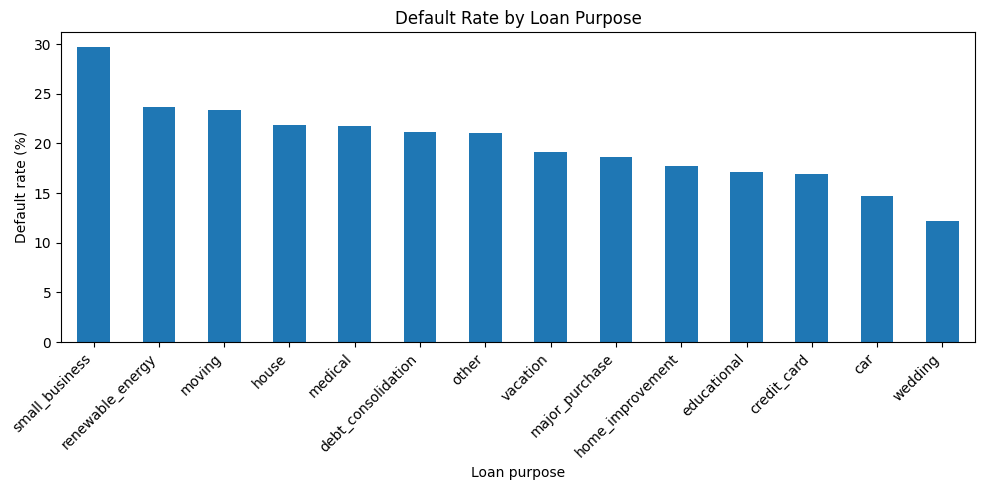

In [22]:
purpose_default_rate = (
    df.groupby("purpose")["target"].mean().sort_values(ascending=False) * 100
)

plt.figure(figsize=(10, 5))
purpose_default_rate.plot(kind="bar")

plt.title("Default Rate by Loan Purpose")
plt.xlabel("Loan purpose")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

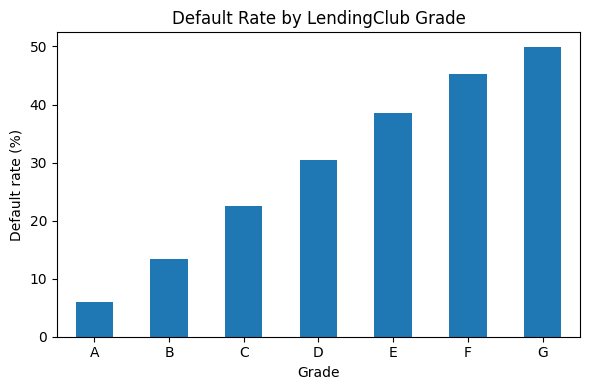

In [23]:
grade_default_rate = (
    df
    .groupby("grade")["target"]
    .mean()
    .sort_index() * 100
)

plt.figure(figsize=(6, 4))
grade_default_rate.plot(kind="bar")

plt.title("Default Rate by LendingClub Grade")
plt.xlabel("Grade")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

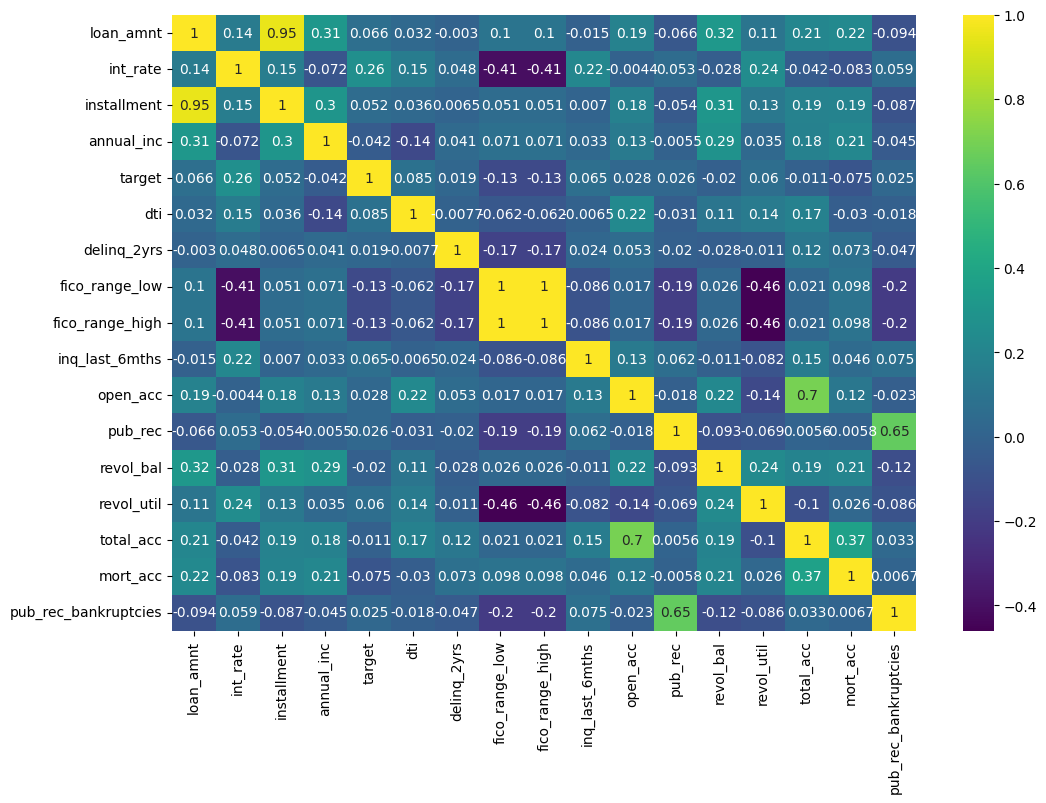

In [24]:
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='viridis')
plt.show()

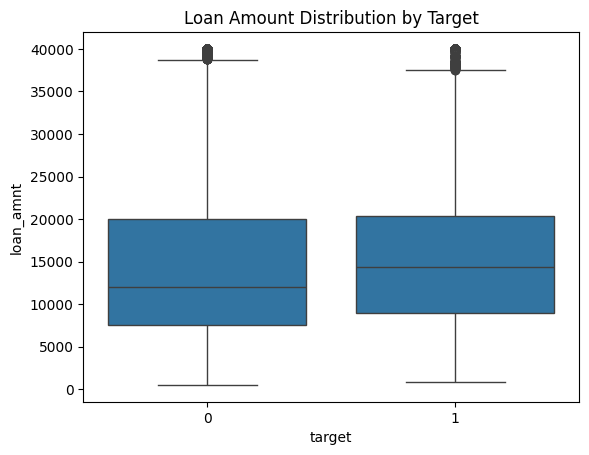

In [25]:
boxplot = sns.boxplot(x="target", y="loan_amnt", data=df)
boxplot.set_title("Loan Amount Distribution by Target")
plt.show()

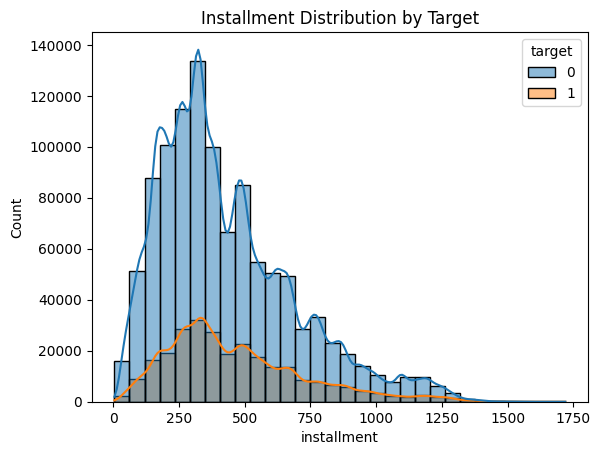

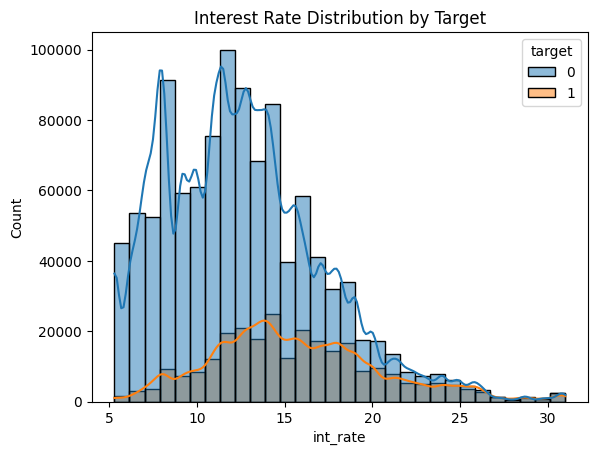

In [26]:
installment = sns.histplot(data=df, x="installment", hue="target", kde=True, bins=30)
installment.set_title("Installment Distribution by Target")

plt.show()

interest_rate = sns.histplot(data=df, x="int_rate", hue="target", kde=True, bins=30)
interest_rate.set_title("Interest Rate Distribution by Target")

plt.show()

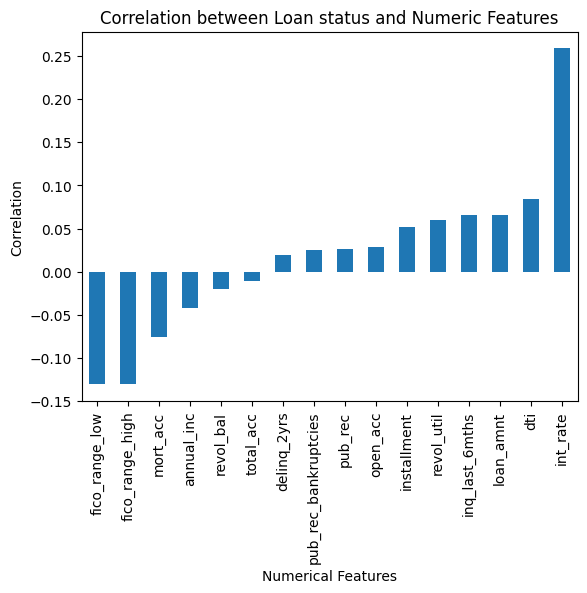

In [27]:
df.corr(numeric_only=True)['target'].drop('target').sort_values().plot(kind='bar',
    title="Correlation between Loan status and Numeric Features", 
    ylabel='Correlation', xlabel='Numerical Features', 
)
plt.show()

# Section 2 DPT

### Convert categorical features into numereric

In [28]:
df.dtypes

loan_amnt               float64
term                     object
int_rate                float64
installment             float64
grade                    object
sub_grade                object
emp_length               object
home_ownership           object
annual_inc              float64
verification_status      object
issue_d                  object
target                    int64
purpose                  object
addr_state               object
dti                     float64
delinq_2yrs             float64
earliest_cr_line         object
fico_range_low          float64
fico_range_high         float64
inq_last_6mths          float64
open_acc                float64
pub_rec                 float64
revol_bal               float64
revol_util              float64
total_acc               float64
initial_list_status      object
application_type         object
mort_acc                float64
pub_rec_bankruptcies    float64
dtype: object

In [29]:
df.application_type.unique()

array(['Individual', 'Joint App'], dtype=object)

Since application type is just two values we binary encode

In [30]:
df['Individual application'] = df['application_type'] == 'INDIVIDUAL'
df.drop(columns=['application_type'], inplace=True)

In [31]:
df.emp_length.unique()

array(['10+ years', '3 years', '4 years', '6 years', '7 years', '8 years',
       '2 years', '5 years', '9 years', '< 1 year', '1 year', nan],
      dtype=object)

employement length we can ordinal encode

In [32]:
df["emp_length"] = df["emp_length"].map({"< 1 year": 0, "1 year": 1, "2 years": 2, "3 years": 3, "4 years": 4, "5 years": 5, "6 years": 6, "7 years": 7, "8 years": 8, "9 years": 9, "10+ years": 10})

In [33]:
df.term.value_counts()

term
36 months    1020743
60 months     324567
Name: count, dtype: int64

For term we kan strip the months and convert to int

In [34]:
df["term"].fillna("36 months", inplace=True)

/tmp/ipykernel_639/2803924516.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["term"].fillna("36 months", inplace=True)


In [35]:
df["term"] = df["term"].str.strip().str.replace(" months", "").astype(int)

In [36]:
df.purpose.value_counts().head()

purpose
debt_consolidation    780321
credit_card           295279
home_improvement       87504
other                  77875
major_purchase         29425
Name: count, dtype: int64

In [37]:
df['verification_status'].value_counts()

verification_status
Source Verified    521273
Verified           418336
Not Verified       405701
Name: count, dtype: int64

In [38]:
df['initial_list_status'].value_counts()

initial_list_status
w    784010
f    561300
Name: count, dtype: int64

In [39]:
df['home_ownership'].value_counts()

home_ownership
MORTGAGE    665579
RENT        534421
OWN         144832
ANY            286
OTHER          144
NONE            48
Name: count, dtype: int64

We also know subgrade is a more detailed version of grade, so we can drop grade.

In [40]:
df.drop('grade', axis=1, inplace=True)

dummies = ['sub_grade', 'verification_status', 'purpose', 'initial_list_status', 'home_ownership', 'addr_state']
df = pd.get_dummies(df, columns=dummies, drop_first=True)



In [41]:
df.dtypes == "object"

loan_amnt                              False
term                                   False
int_rate                               False
installment                            False
emp_length                             False
annual_inc                             False
issue_d                                 True
target                                 False
dti                                    False
delinq_2yrs                            False
earliest_cr_line                        True
fico_range_low                         False
fico_range_high                        False
inq_last_6mths                         False
open_acc                               False
pub_rec                                False
revol_bal                              False
revol_util                             False
total_acc                              False
mort_acc                               False
pub_rec_bankruptcies                   False
Individual application                 False
sub_grade_

In [42]:
df['earliest_cr_line'].head()

0    Aug-2003
1    Dec-1999
2    Aug-2000
4    Jun-1998
5    Oct-1987
Name: earliest_cr_line, dtype: object

In [43]:
df["earliest_cr_line"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")

# Credit history length in years, relative to a fixed reference (dataset ~2018)
reference = pd.Timestamp("2018-01-01")
df["credit_history_yrs"] = (reference - df["earliest_cr_line"]).dt.days / 365.25

df.drop(columns="earliest_cr_line", inplace=True)

We need to drop issue date since it is data leakage as the model would no know if the loan has been approved or not before making its prediction

In [44]:
df.drop('issue_d', axis=1, inplace=True)



## Fill missing values

In [45]:
df.isnull().sum()

loan_amnt                                  0
term                                       0
int_rate                                   0
installment                                0
emp_length                             78511
annual_inc                                 0
target                                     0
dti                                      374
delinq_2yrs                                0
fico_range_low                             0
fico_range_high                            0
inq_last_6mths                             1
open_acc                                   0
pub_rec                                    0
revol_bal                                  0
revol_util                               857
total_acc                                  0
mort_acc                               47281
pub_rec_bankruptcies                     697
Individual application                     0
sub_grade_A2                               0
sub_grade_A3                               0
sub_grade_

We see that multiple row have 33 null values. Are these the same rows?

In [46]:
df[df['loan_amnt'].isnull() == True].isnull().sum()

loan_amnt                              0
term                                   0
int_rate                               0
installment                            0
emp_length                             0
annual_inc                             0
target                                 0
dti                                    0
delinq_2yrs                            0
fico_range_low                         0
fico_range_high                        0
inq_last_6mths                         0
open_acc                               0
pub_rec                                0
revol_bal                              0
revol_util                             0
total_acc                              0
mort_acc                               0
pub_rec_bankruptcies                   0
Individual application                 0
sub_grade_A2                           0
sub_grade_A3                           0
sub_grade_A4                           0
sub_grade_A5                           0
sub_grade_B1    

Yess these rows contain a lot of null vallues lets drop them

In [47]:
df = df.dropna(subset=['loan_amnt'])

In [48]:
df.isnull().sum()

loan_amnt                                  0
term                                       0
int_rate                                   0
installment                                0
emp_length                             78511
annual_inc                                 0
target                                     0
dti                                      374
delinq_2yrs                                0
fico_range_low                             0
fico_range_high                            0
inq_last_6mths                             1
open_acc                                   0
pub_rec                                    0
revol_bal                                  0
revol_util                               857
total_acc                                  0
mort_acc                               47281
pub_rec_bankruptcies                     697
Individual application                     0
sub_grade_A2                               0
sub_grade_A3                               0
sub_grade_

In [49]:
df = df.dropna(subset=["target"])

Define imputer to fill the rest of the missing values

In [50]:
from sklearn.impute import SimpleImputer


num_cols = df.select_dtypes(include="number").columns.drop("target")
cols_to_impute = num_cols[df[num_cols].isnull().any()].tolist()
print("Numeric columns to impute:", cols_to_impute)

imputer = SimpleImputer(strategy="median")
df[cols_to_impute] = imputer.fit_transform(df[cols_to_impute])

Numeric columns to impute: ['emp_length', 'dti', 'inq_last_6mths', 'revol_util', 'mort_acc', 'pub_rec_bankruptcies']


### This dataset does not have that much class imbalance. For our research we want class imbalce, so we will randomly undersample to get the minority class to 1%

In [51]:
minority_frac = 0.01

majority = df[df["target"] == 0]
minority = df[df["target"] == 1]

n_minority = int(round(minority_frac / (1 - minority_frac) * len(majority)))

minority_down = minority.sample(n=n_minority, random_state=RANDOM_STATE)

df_imbalanced = (
    pd.concat([majority, minority_down])
    .sample(frac=1, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

print(df_imbalanced["target"].value_counts())
print(df_imbalanced["target"].value_counts(normalize=True))  # ~0.99 / 0.01


target
0    1076751
1      10876
Name: count, dtype: int64
target
0    0.99
1    0.01
Name: proportion, dtype: float64


Finally split into Test and Train

In [52]:
train_df, test_df = train_test_split(df_imbalanced, test_size=0.2, random_state=RANDOM_STATE)

In [53]:
X_train = train_df.drop(columns="target")
y_train = train_df["target"]
X_test = test_df.drop(columns="target")
y_test = test_df["target"]

Scale the data

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Section 3 resampling

For oversampling we will use:
- Class weighting (cost-sensitive Learning)
- Random Under-Sampling
- SMOTE-ENN (Edited Nearest Neighbour)
- K-Means SMOTE



In [55]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.combine import SMOTEENN
from imblearn.over_sampling import KMeansSMOTE
from sklearn.model_selection import StratifiedKFold
from sklearn.cluster import MiniBatchKMeans

In [56]:
samplers = {
    "Baseline": None,   
    "RandomUnderSampler": RandomUnderSampler(sampling_strategy="majority", random_state=RANDOM_STATE),
    "SMOTEENN":           SMOTEENN(sampling_strategy="minority", random_state=RANDOM_STATE),
    "KMeansSMOTE": KMeansSMOTE(
        sampling_strategy="minority",
        random_state=RANDOM_STATE,
        cluster_balance_threshold=0.01,
        kmeans_estimator=MiniBatchKMeans(n_clusters=100, random_state=RANDOM_STATE, n_init=3),
    ),
    "ClassWeight":        None,
}

In [57]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Section 4 Model Implementation

We will implement the following models that have surfaced in the literature review:
- Random forest
- Logistic regression
- XGBoost
- Neural Network

In [58]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from torch import nn


from sklearn.model_selection import cross_validate
from time import process_time


In [ ]:
results = []

def model_kfold(sampler_name, sampler, estimator, X, y):
    print(f"Training {estimator.__class__.__name__} + {sampler_name}...")
    steps = [
        
    ]
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("clf", estimator))
    pipe = ImbPipeline(steps)

    cv_out = cross_validate(
        pipe, X, y, cv=skf,
        scoring=("f1_macro", "roc_auc", "average_precision", "recall_macro", "precision_macro"),
        return_train_score=False,
    )
    results.append({
        "Model": estimator.__class__.__name__,
        "Sampler": sampler_name,
        "fit time (s)": round(cv_out["fit_time"].mean(), 2),
        "Score time (s)": round(cv_out["score_time"].mean(), 2),
        "F1 (mean)":        cv_out["test_f1_macro"].mean(),
        "ROC-AUC (mean)":   cv_out["test_roc_auc"].mean(),
        "PR-AUC (mean)":    cv_out["test_average_precision"].mean(),
        "Recall (mean)":    cv_out["test_recall_macro"].mean(),
        "Precision (mean)": cv_out["test_precision_macro"].mean(),
    })

In [60]:
def loop_samplers(estimator, X, y):
    for sampler_name, sampler in samplers.items():
        if sampler_name == "ClassWeight":
            if estimator.__class__.__name__ in ["LogisticRegression", "RandomForestClassifier"]:
                estimator.set_params(class_weight="balanced")
            elif estimator.__class__.__name__ == "XGBClassifier":
                estimator.set_params(scale_pos_weight=(y == 0).sum() / (y == 1).sum())
        model_kfold(sampler_name, sampler, estimator, X, y)

In [ ]:
loop_samplers(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'), X_train_scaled, y_train)

Training XGBClassifier + Baseline...


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Training XGBClassifier + RandomUnderSampler...
Training XGBClassifier + SMOTEENN...


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packag

Training XGBClassifier + KMeansSMOTE...
Training XGBClassifier + ClassWeight...


In [ ]:
loop_samplers(LogisticRegression(random_state=RANDOM_STATE, max_iter=1000), X_train_scaled, y_train)


Training LogisticRegression + Baseline...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWa

Training LogisticRegression + RandomUnderSampler...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

Training LogisticRegression + SMOTEENN...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

Training LogisticRegression + KMeansSMOTE...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

Training LogisticRegression + ClassWeight...


/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.10/dist-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refe

In [63]:
loop_samplers(RandomForestClassifier(random_state=RANDOM_STATE), X_train, y_train)

Training RandomForestClassifier + Baseline...


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packag

Training RandomForestClassifier + RandomUnderSampler...
Training RandomForestClassifier + SMOTEENN...


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packag

Training RandomForestClassifier + KMeansSMOTE...


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packag

Training RandomForestClassifier + ClassWeight...


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/usr/local/lib/python3.10/dist-packag

In [64]:
model_results = pd.DataFrame(results)
model_results.to_csv("model_results.csv", index=False)
model_results

,Model,Sampler,fit time (s),Score time (s),F1 (mean),ROC-AUC (mean),PR-AUC (mean),Recall (mean),Precision (mean)
0,XGBClassifier,Baseline,155.38,0.55,0.497480,0.693786,0.023016,0.499996,0.494990
1,XGBClassifier,RandomUnderSampler,159.91,0.58,0.400714,0.687738,0.022617,0.634685,0.505688
2,XGBClassifier,SMOTEENN,570.53,0.34,0.497482,0.686580,0.021770,0.499999,0.494990
3,XGBClassifier,KMeansSMOTE,11.27,0.19,0.497706,0.678201,0.020653,0.500104,0.521658
4,XGBClassifier,ClassWeight,1.55,0.20,0.453360,0.680383,0.023141,0.622046,0.506788
5,LogisticRegression,Baseline,76.95,0.27,0.497481,0.700380,0.023960,0.499997,0.494990
6,LogisticRegression,RandomUnderSampler,1.43,0.27,0.425541,0.705827,0.024262,0.647882,0.506806
7,LogisticRegression,SMOTEENN,537.09,0.27,0.410011,0.700797,0.023520,0.644366,0.506257
8,LogisticRegression,KMeansSMOTE,171.45,0.27,0.469551,0.601950,0.016584,0.565338,0.504607
9,LogisticRegression,ClassWeight,93.01,0.30,0.423714,0.705116,0.024247,0.646319,0.506681


Implement Neural Network

In [65]:
class NeuralNetwork(nn.Module):

    def __init__(self):
        super().__init__()
        self.layer_1 = nn.Linear(X_train.shape[1], 256)   
        self.activation_1 = nn.ReLU()  
        self.dropout_1 = nn.Dropout(0.2)        
        self.layer_2 = nn.Linear(256, 256)        
        self.activation_2 = nn.ReLU()
        self.dropout_2 = nn.Dropout(0.2) 
        self.layer_3 = nn.Linear(256, 256)        
        self.activation_3 = nn.ReLU()
        self.dropout_3 = nn.Dropout(0.2)
        self.layer_4 = nn.Linear(256, 2)        
        self.activation_4 = nn.Sigmoid() 

    def forward(self, X):
        X = self.layer_1(X)
        X = self.activation_1(X)
        X = self.dropout_1(X)
        X = self.layer_2(X)
        X = self.activation_2(X)
        X = self.dropout_2(X)
        X = self.layer_3(X)
        X = self.activation_3(X)
        X = self.dropout_3(X)
        X = self.layer_4(X)
        X = self.activation_4(X)
        return X
    
nn_model = NeuralNetwork()
print(nn_model)

NeuralNetwork(
  (layer_1): Linear(in_features=125, out_features=256, bias=True)
  (activation_1): ReLU()
  (dropout_1): Dropout(p=0.2, inplace=False)
  (layer_2): Linear(in_features=256, out_features=256, bias=True)
  (activation_2): ReLU()
  (dropout_2): Dropout(p=0.2, inplace=False)
  (layer_3): Linear(in_features=256, out_features=256, bias=True)
  (activation_3): ReLU()
  (dropout_3): Dropout(p=0.2, inplace=False)
  (layer_4): Linear(in_features=256, out_features=2, bias=True)
  (activation_4): Sigmoid()
)


In [ ]:
# Imports
from torch.nn import CrossEntropyLoss
from torch.optim import Adam
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm

# Training the network
net = NeuralNetwork()

# We use Cross Entropy Loss for this example
criterion = CrossEntropyLoss(reduction='mean')
# We use the Adam optimizer on the parameters of our network and define the learning rate (other parameters may be defined as well)
optimizer = Adam(net.parameters(), lr=0.001)

# Define how we train during an epoch
def train_single_epoch(network: nn.Module, dataset: TensorDataset) -> nn.Module:
    # Define a data loader, allowing us to shuffle data and provide a batch size
    data = DataLoader(dataset, batch_size=32, shuffle=True)
    # Add a progress bar around dataset (optional)
    data = tqdm(data, desc='Training')

    # Loop over data in dataset
    for X_train, y_true in data:
        # Clear any remaining tracking of gradients for backpropagation
        optimizer.zero_grad()
        # Do forward propagation by making a prediction
        y_pred = network(X_train)
        # Compute loss between predicted output and actual output
        loss = criterion(y_pred, y_true)
        # Backpropagate loss
        loss.backward()
        # Let the optimizer take a step
        optimizer.step()

    # Return the updated network
    return network

# We can train for multiple epochs
for epoch in range(1):
    net = train_single_epoch(net, TensorDataset(X_train, y_train))

fakka tim 